# Computer Vision - Capstone (Bai tap tong hop)

One real scene analyzed end to end: preprocessing, geometric structure, content analysis, visualization. The code is in `src/tonghop_*.py`.

## Setup

Install dependencies from the repository root with `python -m pip install -r requirements.txt`.

For Google Colab, run `!git clone https://github.com/nghoang1162050/CO3057-BTL_17.git`, then `%cd CO3057-BTL_17`, then `!pip install -r requirements.txt` before running this notebook.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd()
if not (repo_root / "src").is_dir():
    repo_root = repo_root.parent
if not (repo_root / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the repository root or notebooks/ directory")
sys.path.insert(0, str(repo_root / "src"))

import matplotlib.pyplot as plt
import matplotlib.image as mpimg


def show(path, figsize=(14, 5)):
    plt.figure(figsize=figsize)
    plt.imshow(mpimg.imread(repo_root / path))
    plt.axis("off")
    plt.show()

## Run the pipeline

`tonghop_pipeline.run()` loads the first photo in `data/tonghop_scene/` (the `camera` sample from scikit-image if the folder is empty), then:

1. **3.1** CLAHE on the Lab lightness channel, bilateral denoising, grayscale.
2. **3.2** Canny edges, the 25 longest probabilistic Hough segments, Shi-Tomasi corners.
3. **3.3** Spectral-residual saliency, its bounding box as the seed rectangle, GrabCut.
4. **3.4** Before/after figures.

In [2]:
import tonghop_pipeline as tp

tp.run(out_dir=repo_root / "outputs" / "tonghop_scene")

[Tonghop] Using custom scene image: D:\git_pet\computer-vision\CO3057-BTL_17\src\..\data\tonghop_scene\ban_cong.jpg


[Tonghop] Preprocessing: grayscale contrast (std) 58.51 -> 68.03 after CLAHE
[Tonghop] Geometry: 25 lines, 60 corners in 23.2 ms
[Tonghop] Content: saliency+GrabCut in 3216.4 ms, foreground = 35.8% of image
[Tonghop] Figures written to D:\git_pet\computer-vision\CO3057-BTL_17\outputs\tonghop_scene


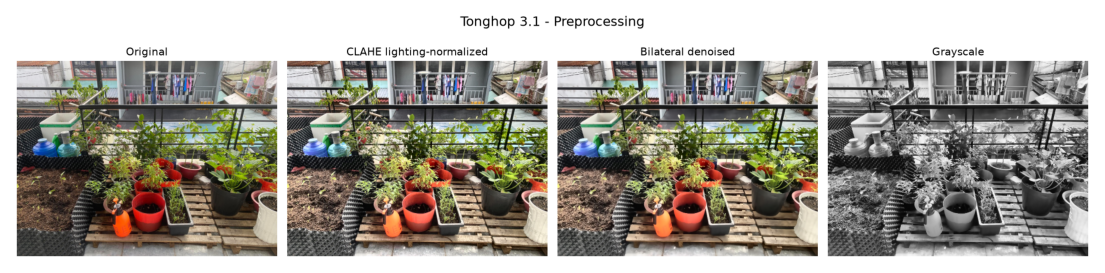

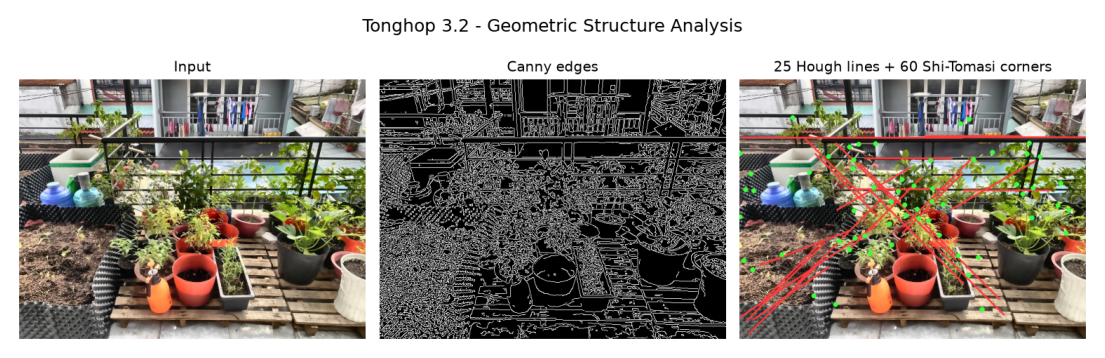

In [3]:
show("outputs/tonghop_scene/00_preprocess.png")
show("outputs/tonghop_scene/01_geometry.png")

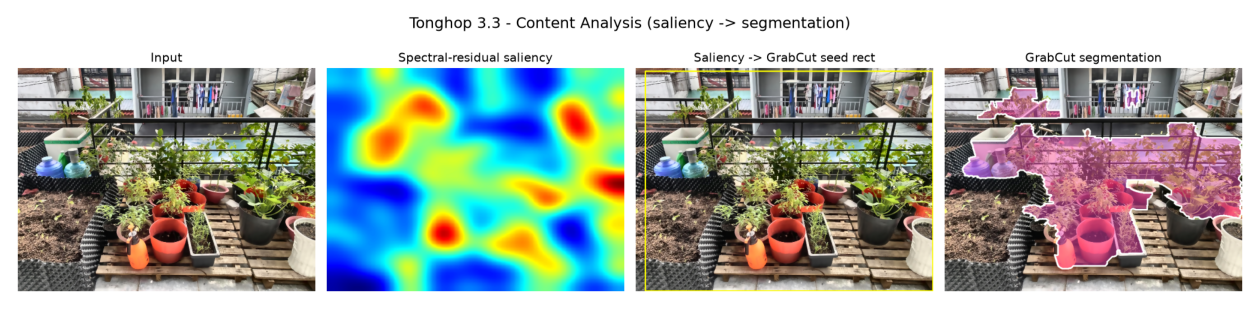

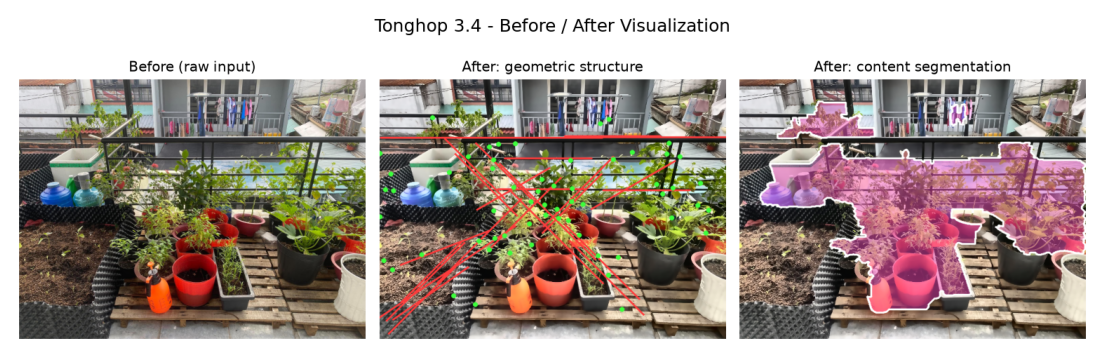

In [4]:
show("outputs/tonghop_scene/02_content.png", figsize=(16, 5))
show("outputs/tonghop_scene/03_before_after.png")